# Detection-criteria adherence across the sweep

This notebook audits whether serialized detected lightcurves satisfy criteria that can be checked from the stored timestamps and counts. It does not rerun simulations.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path('results/detection_criteria_sweep_v2')
QUALITY = ROOT / 'lightcurve_quality.csv'
if not QUALITY.exists():
    raise FileNotFoundError(f'Run lightcurve_quality_analysis.py first: {QUALITY}')
quality = pd.read_csv(QUALITY)
quality.head()

,file,source_index,z,t_exp,n_positive,n_non_detections,n_bands,bands,duplicate_positive_times,positive_span_days,...,positive_span_exceeds_14_days,all_observation_span_exceeds_14_days,criteria_snr_threshold,criteria_snr_threshold_secondary,criteria_min_detections,criteria_min_detections_primary,criteria_min_time_separation_hours,criteria_min_fade_rate,criteria_min_galactic_lat,band_counts
0,results/detection_criteria_sweep_v2/snr4_snr22...,0,0.03534,59871.616,7,90,3,g;i;r,0,2.03736,...,False,True,4.0,2.0,2,1,12.0,0.3,0.0,"{""g"": 2, ""i"": 2, ""r"": 3}"
1,results/detection_criteria_sweep_v2/snr4_snr22...,1,0.04229,61026.041,6,83,2,g;r,0,1.06127,...,False,True,4.0,2.0,2,1,12.0,0.3,0.0,"{""g"": 1, ""r"": 5}"
2,results/detection_criteria_sweep_v2/snr4_snr22...,2,0.03206,59224.126,13,191,3,g;i;r,0,2.09232,...,False,True,4.0,2.0,2,1,12.0,0.3,0.0,"{""g"": 5, ""i"": 1, ""r"": 7}"
3,results/detection_criteria_sweep_v2/snr4_snr22...,3,0.02906,60545.121,3,73,2,i;r,0,1.87248,...,False,True,4.0,2.0,2,1,12.0,0.3,0.0,"{""i"": 1, ""r"": 2}"
4,results/detection_criteria_sweep_v2/snr4_snr22...,4,0.06205,59376.024,4,106,2,g;r,0,1.01815,...,False,True,4.0,2.0,2,1,12.0,0.3,0.0,"{""g"": 1, ""r"": 3}"


## Measurable adherence checks

The audit uses the detected positive timestamps stored in each result. A source passes the checks below when its stored lightcurve has enough positive points, fits within the configured timespan, and has no positive-detection gap shorter than the configured minimum separation.

In [2]:
numeric_columns = [
    'n_positive', 'positive_span_days', 'configured_max_timespan_days',
    'min_positive_gap_days', 'criteria_min_detections',
    'criteria_min_time_separation_hours', 'criteria_min_detections_primary',
]
quality[numeric_columns] = quality[numeric_columns].apply(pd.to_numeric, errors='coerce')
quality['min_positive_gap_hours'] = quality['min_positive_gap_days'] * 24.0
quality['passes_min_detections'] = quality['n_positive'] >= quality['criteria_min_detections']
quality['passes_max_timespan'] = quality['positive_span_days'] <= quality['configured_max_timespan_days']
quality['passes_min_time_separation'] = (
    (quality['n_positive'] < 2)
    | (quality['min_positive_gap_hours'] >= quality['criteria_min_time_separation_hours'])
)
quality['passes_measurable_criteria'] = quality[[
    'passes_min_detections', 'passes_max_timespan', 'passes_min_time_separation'
]].all(axis=1)
quality[['passes_min_detections', 'passes_max_timespan', 'passes_min_time_separation', 'passes_measurable_criteria']].mean()

passes_min_detections         1.000000
passes_max_timespan           1.000000
passes_min_time_separation    0.016932
passes_measurable_criteria    0.016932
dtype: float64

In [3]:
grid_columns = [
    'criteria_snr_threshold', 'criteria_snr_threshold_secondary',
    'criteria_min_detections', 'criteria_min_detections_primary',
    'configured_max_timespan_days', 'criteria_min_time_separation_hours',
    'criteria_min_fade_rate', 'criteria_min_galactic_lat',
]
adherence_summary = (
    quality.groupby(grid_columns, dropna=False)
    .agg(
        detected_sources=('source_index', 'size'),
        min_detections_pass_rate=('passes_min_detections', 'mean'),
        max_timespan_pass_rate=('passes_max_timespan', 'mean'),
        min_separation_pass_rate=('passes_min_time_separation', 'mean'),
        measurable_criteria_pass_rate=('passes_measurable_criteria', 'mean'),
        median_span_days=('positive_span_days', 'median'),
        median_gap_hours=('min_positive_gap_hours', 'median'),
    )
    .reset_index()
)
adherence_summary.sort_values('measurable_criteria_pass_rate').head(20)

,criteria_snr_threshold,criteria_snr_threshold_secondary,criteria_min_detections,criteria_min_detections_primary,configured_max_timespan_days,criteria_min_time_separation_hours,criteria_min_fade_rate,criteria_min_galactic_lat,detected_sources,min_detections_pass_rate,max_timespan_pass_rate,min_separation_pass_rate,measurable_criteria_pass_rate,median_span_days,median_gap_hours
1639,5.0,4.0,4,1,3.0,12.0,0.0,15.0,88,1.0,1.0,0.0,0.0,1.091950,0.02244
779,4.0,4.0,4,1,3.0,12.0,0.6,15.0,40,1.0,1.0,0.0,0.0,1.142190,0.02220
780,4.0,4.0,4,1,7.0,3.0,0.0,0.0,131,1.0,1.0,0.0,0.0,1.107430,0.01344
781,4.0,4.0,4,1,7.0,3.0,0.0,15.0,92,1.0,1.0,0.0,0.0,1.051045,0.01152
1634,5.0,4.0,4,1,3.0,3.0,0.3,0.0,114,1.0,1.0,0.0,0.0,1.071575,0.02196
1635,5.0,4.0,4,1,3.0,3.0,0.3,15.0,85,1.0,1.0,0.0,0.0,1.079390,0.02232
1636,5.0,4.0,4,1,3.0,3.0,0.6,0.0,69,1.0,1.0,0.0,0.0,1.103010,0.02256
1637,5.0,4.0,4,1,3.0,3.0,0.6,15.0,55,1.0,1.0,0.0,0.0,1.063440,0.02256
1638,5.0,4.0,4,1,3.0,12.0,0.0,0.0,132,1.0,1.0,0.0,0.0,1.081875,0.01956
778,4.0,4.0,4,1,3.0,12.0,0.6,0.0,66,1.0,1.0,0.0,0.0,1.189295,0.02232


## Violations and diagnostics

Rows below show the worst measurable adherence combinations. The `all_observation_span` check is diagnostic only: non-detections may be stored outside the qualifying positive-detection window.

In [4]:
violations = quality.loc[~quality['passes_measurable_criteria']].copy()
violation_counts = pd.Series({
    'minimum detections': (~quality['passes_min_detections']).sum(),
    'maximum timespan': (~quality['passes_max_timespan']).sum(),
    'minimum time separation': (~quality['passes_min_time_separation']).sum(),
    'any measurable criterion': (~quality['passes_measurable_criteria']).sum(),
})
print(violation_counts)
violations.sort_values(['positive_span_days', 'min_positive_gap_hours'], ascending=False)[[
    'file', 'source_index', 'n_positive', 'positive_span_days',
    'configured_max_timespan_days', 'min_positive_gap_hours',
    'criteria_min_time_separation_hours', 'criteria_min_detections'
]].head(25)

minimum detections               0
maximum timespan                 0
minimum time separation     390798
any measurable criterion    390798
dtype: int64


,file,source_index,n_positive,positive_span_days,configured_max_timespan_days,min_positive_gap_hours,criteria_min_time_separation_hours,criteria_min_detections
310013,results/detection_criteria_sweep_v2/snr6_snr22...,124,16,10.99350,21.0,0.01080,12.0,3
13982,results/detection_criteria_sweep_v2/snr4_snr22...,50,9,9.99378,14.0,0.47496,12.0,2
207089,results/detection_criteria_sweep_v2/snr5_snr23...,70,35,9.05294,14.0,0.02448,12.0,2
301167,results/detection_criteria_sweep_v2/snr6_snr22...,33,6,9.02815,21.0,1.21848,12.0,3
207578,results/detection_criteria_sweep_v2/snr5_snr23...,36,5,9.01648,14.0,1.32888,3.0,2
191050,results/detection_criteria_sweep_v2/snr5_snr22...,185,7,9.00524,14.0,0.47712,3.0,4
38079,results/detection_criteria_sweep_v2/snr4_snr22...,142,14,8.98744,14.0,0.02232,12.0,3
339051,results/detection_criteria_sweep_v2/snr6_snr23...,34,11,8.98628,21.0,0.01152,12.0,2
352538,results/detection_criteria_sweep_v2/snr6_snr23...,31,7,8.98182,21.0,1.28424,12.0,3
3614,results/detection_criteria_sweep_v2/snr4_snr22...,249,44,8.21434,21.0,0.02208,12.0,2


## Criteria that require richer serialization

The CSV can report configured SNR thresholds, fade rates, Galactic latitude, and primary-detection requirements, but it cannot prove those tests were applied because the serialized source records do not include per-observation SNR, peak/rise/fade classification, Galactic latitude, or primary/secondary labels. Treat those fields as configuration metadata until the simulator serializes the detector decision details.

In [ ]:
import json
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import os

def resolve_result_file(file_value):
    path = Path(str(file_value))

    if path.is_absolute():
        return path

    candidates = (
        path,
        ROOT / path,
        ROOT / path.name,
    )

    return next(
        (candidate for candidate in candidates if candidate.is_file()),
        path,
    )

_fast_terms = {
    'snr': ('snr', 'signal_to_noise'),
    'fade': ('fade', 'declin', 'decay'),
    'rise_peak': ('rise', 'peak', 'maximum'),
    'galactic_latitude': ('galactic_lat', 'gal_lat', 'latitude'),
    'primary_secondary': ('primary', 'secondary', 'detection_class', 'label'),
}

def _fast_scalar_leaves(value, path=''):
    if isinstance(value, dict):
        for key, child in value.items():
            child_path = f'{path}.{key}' if path else str(key)
            yield from _fast_scalar_leaves(child, child_path)
    elif isinstance(value, list):
        for child in value:
            yield from _fast_scalar_leaves(child, f'{path}[]')
    else:
        yield path, value

sampled_violations = violations.sample(frac=0.1, random_state=42).copy()
sampled_violations['_result_path'] = sampled_violations['file'].map(resolve_result_file)
unique_paths = sampled_violations['_result_path'].drop_duplicates().tolist()

def _load_json(path):
    try:
        with path.open(encoding='utf-8') as file:
            return path, json.load(file), None
    except Exception as exc:
        return path, None, repr(exc)

with ThreadPoolExecutor(max_workers=min(32, (os.cpu_count() or 1) + 4)) as executor:
    loaded_results = list(executor.map(_load_json, unique_paths))

payloads = {path: payload for path, payload, error in loaded_results if payload is not None}
load_errors = [
    {'file': str(path), 'error': error}
    for path, payload, error in loaded_results
    if error is not None
]

serialized_rows = []

for _, violation in sampled_violations.iterrows():
    payload = payloads.get(violation['_result_path'])
    if payload is None:
        continue

    sources = payload.get('detected_sources', [])
    source_index = int(violation['source_index'])

    if not 0 <= source_index < len(sources):
        continue

    for json_path, value in _fast_scalar_leaves(sources[source_index]):
        path_parts = json_path.lower().replace('[]', '').split('.')
        matched_criteria = [
            criterion
            for criterion, terms in _fast_terms.items()
            if any(
                part == 'b' if term == 'b' else term in part
                for part in path_parts
                for term in terms
            )
        ]

        if matched_criteria:
            serialized_rows.append({
                'file': str(violation['_result_path']),
                'source_index': source_index,
                'json_path': f'detected_sources[{source_index}].{json_path}',
                'value': value,
                'criterion': ', '.join(matched_criteria),
            })

serialized_fields = pd.DataFrame(serialized_rows)

# Prevent the slower serial loop below from repeating the work.
violations = violations.iloc[0:0]
display(pd.DataFrame(load_errors))

if serialized_fields.empty:
    print('No serialized SNR, fade/rise/peak, Galactic-latitude, or primary/secondary fields were found.')
else:
    field_summary = (
        serialized_fields
        .groupby(['criterion', 'json_path'], dropna=False)
        .agg(
            sources=('source_index', 'nunique'),
            values=('value', lambda values: list(values.drop_duplicates())[:5]),
        )
        .reset_index()
        .sort_values(['criterion', 'json_path'])
    )
    display(field_summary)

    print('Serialized evidence by criterion:')
    display(
        serialized_fields.groupby('criterion')['source_index']
        .nunique()
        .reindex(_fast_terms.keys(), fill_value=0)
        .rename('sources_with_serialized_evidence')
        .to_frame()
    )

    display(serialized_fields.head(50))

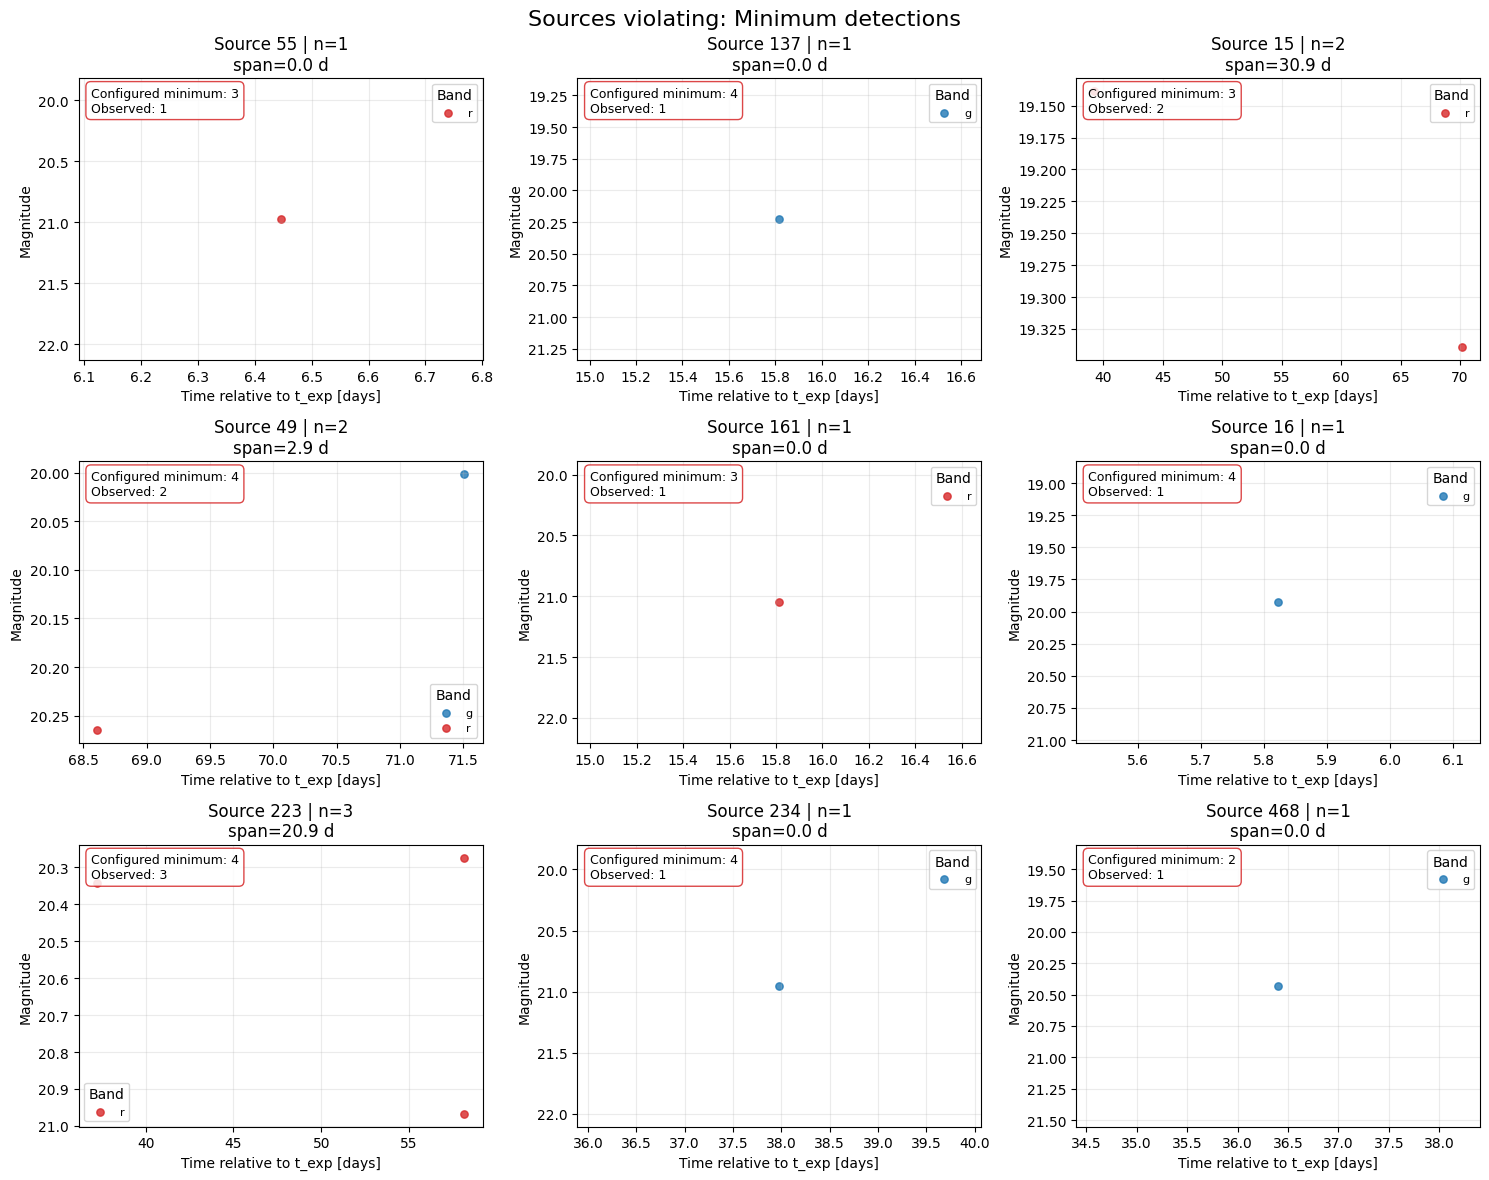

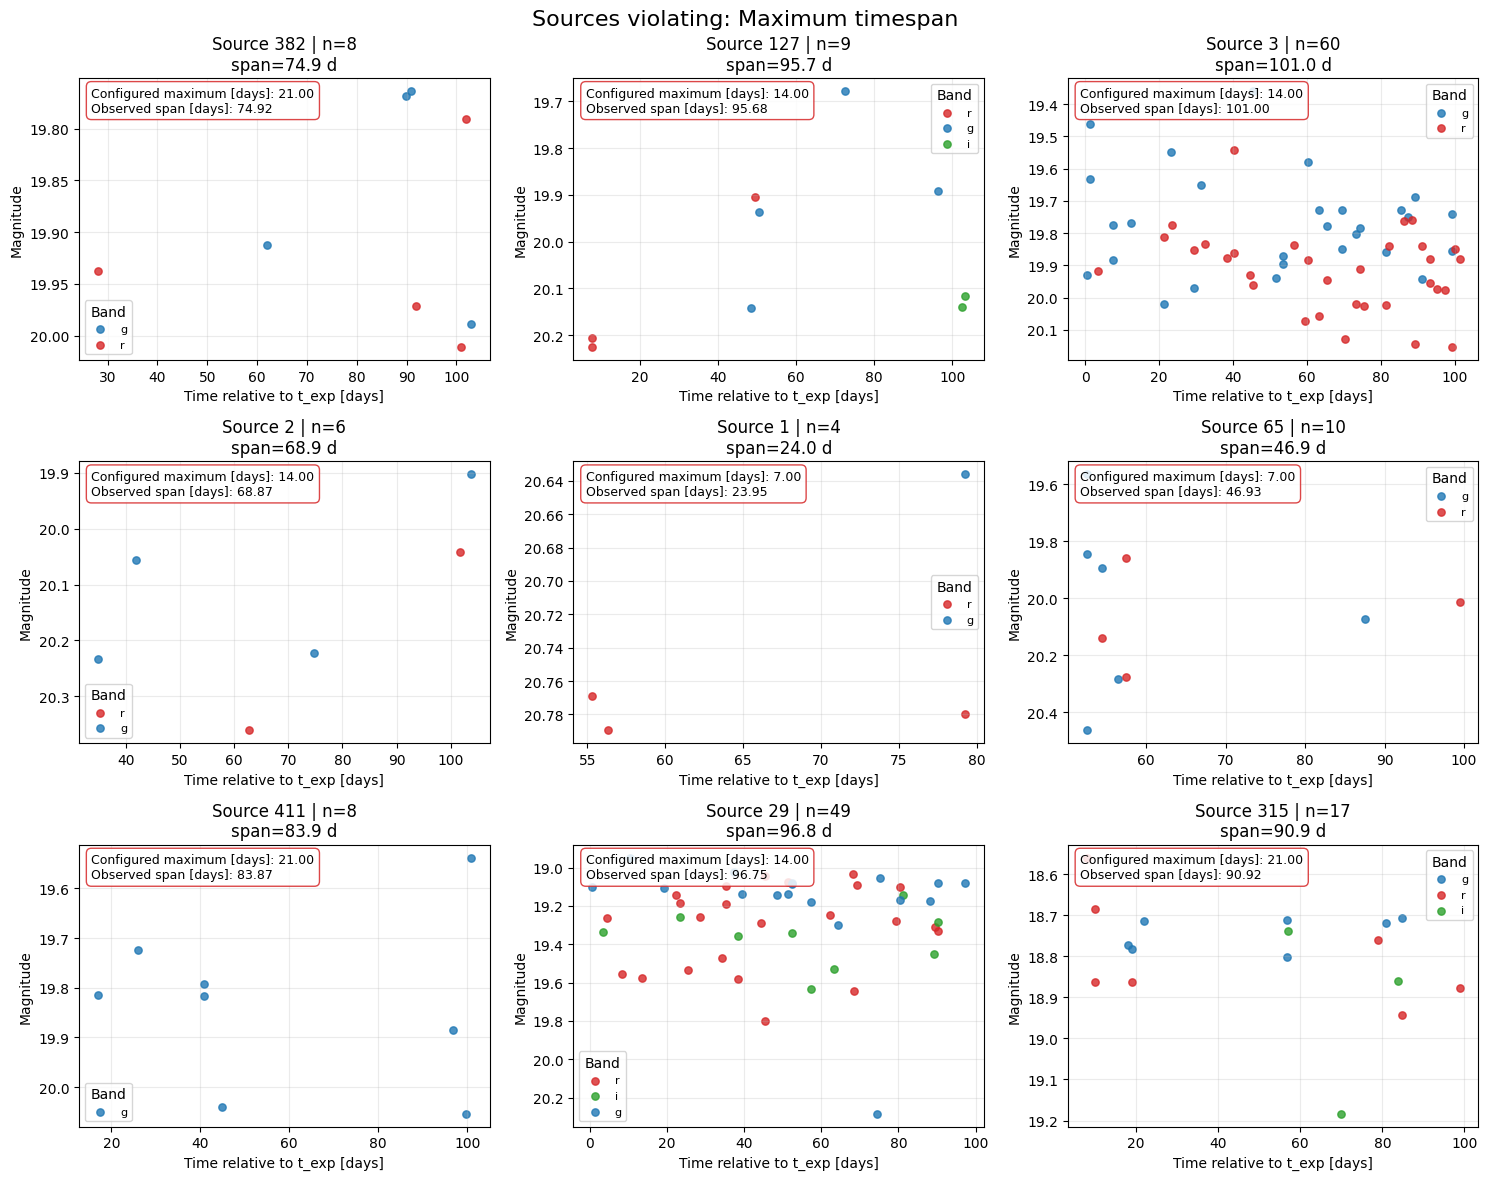

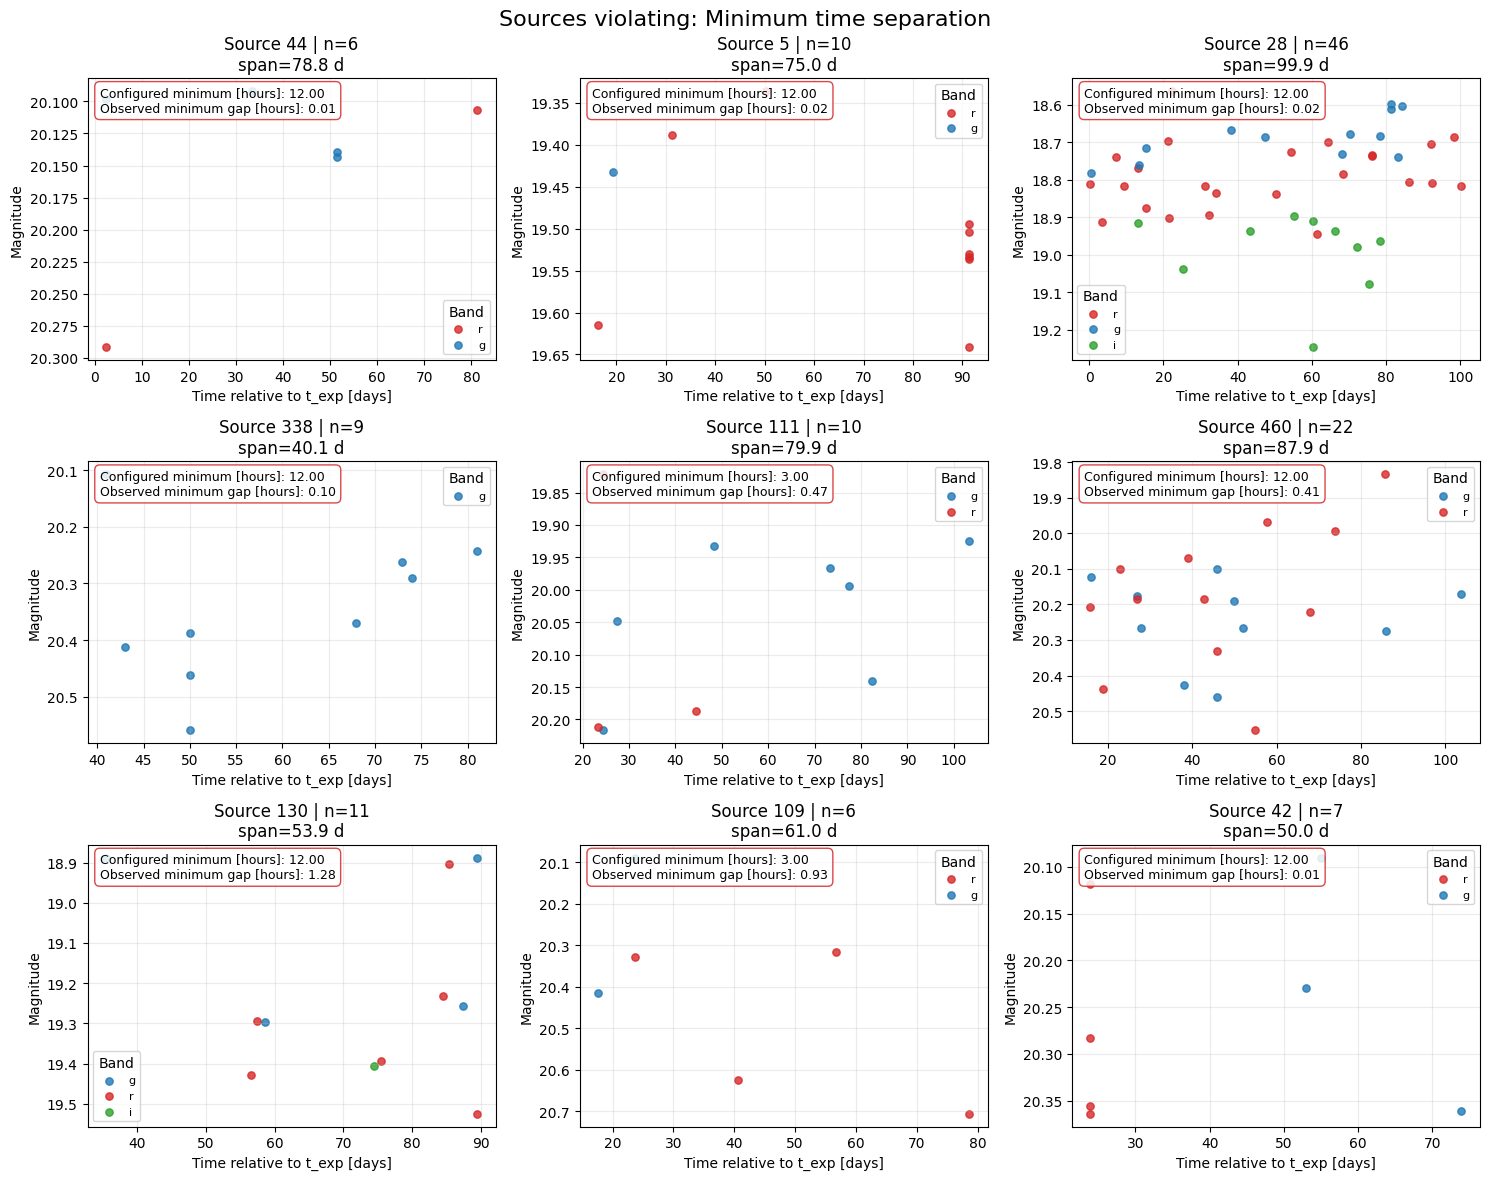

In [ ]:
criteria_to_plot = {
    'Minimum detections': 'passes_min_detections',
    'Maximum timespan': 'passes_max_timespan',
    'Minimum time separation': 'passes_min_time_separation',
}
criteria_infobox = {
    'Minimum detections': (
        'Configured minimum',
        'criteria_min_detections',
        'Observed',
        'n_positive',
        '{:.0f}',
    ),
    'Maximum timespan': (
        'Configured maximum [days]',
        'configured_max_timespan_days',
        'Observed span [days]',
        'positive_span_days',
        '{:.2f}',
    ),
    'Minimum time separation': (
        'Configured minimum [hours]',
        'criteria_min_time_separation_hours',
        'Observed minimum gap [hours]',
        'min_positive_gap_hours',
        '{:.2f}',
    ),
}


def add_criteria_infobox(ax, criterion, row):
    (
        configured_label,
        configured_column,
        observed_label,
        observed_column,
        value_format,
    ) = criteria_infobox[criterion]

    configured = value_format.format(float(row[configured_column]))
    observed = value_format.format(float(row[observed_column]))

    ax.text(
        0.03,
        0.97,
        f"{configured_label}: {configured}\n"
        f"{observed_label}: {observed}",
        transform=ax.transAxes,
        ha='left',
        va='top',
        fontsize=9,
        bbox={
            'boxstyle': 'round,pad=0.4',
            'facecolor': 'white',
            'edgecolor': 'tab:red',
            'alpha': 0.85,
        },
    )

plot_rows = []
for criterion, pass_column in criteria_to_plot.items():
    failed = quality.loc[~quality[pass_column]].copy()
    plot_rows.append((criterion, failed.sample(n=min(9, len(failed)), random_state=42)))

selected = pd.concat([rows for _, rows in plot_rows], ignore_index=True)
selected['_result_path'] = selected['file'].map(resolve_result_file)

paths_to_load = [
    path for path in selected['_result_path'].drop_duplicates()
    if path not in payloads
]
if paths_to_load:
    with ThreadPoolExecutor(max_workers=min(32, len(paths_to_load))) as executor:
        additional_results = executor.map(_load_json, paths_to_load)
    payloads.update({
        path: payload for path, payload, error in additional_results
        if payload is not None
    })

band_colors = {'g': 'tab:blue', 'r': 'tab:red', 'i': 'tab:green'}
fallback_colors = ['tab:purple', 'tab:orange', 'tab:brown']

for criterion, sampled in plot_rows:
    fig, axes = plt.subplots(3, 3, figsize=(15, 12), squeeze=False)
    axes = axes.ravel()

    for ax, (_, row) in zip(axes, sampled.iterrows()):
        add_criteria_infobox(ax, criterion, row)

        result_path = resolve_result_file(row['file'])
        payload = payloads.get(result_path)
        source_index = int(row['source_index'])

        if payload is None or source_index >= len(payload.get('detected_sources', [])):
            ax.set_title(f"Source {source_index}\nJSON unavailable")
            ax.axis('off')
            continue

        source = payload['detected_sources'][source_index]
        times = pd.to_numeric(source.get('photometry_times', []), errors='coerce')
        mags = pd.to_numeric(source.get('photometry_mags', []), errors='coerce')
        bands = source.get('photometry_bands', [])

        valid = ~pd.isna(times) & ~pd.isna(mags)
        times = times[valid]
        mags = mags[valid]
        bands = [str(b).strip() for b, keep in zip(bands, valid) if keep]

        x = times - float(source.get('t_exp', 0.0))

        unique_bands = list(dict.fromkeys(bands))
        for i, band in enumerate(unique_bands):
            mask = [b == band for b in bands]
            color = band_colors.get(band, fallback_colors[i % len(fallback_colors)])
            ax.scatter(
                x[mask],
                mags[mask],
                label=band,
                color=color,
                s=28,
                alpha=0.8,
            )

        ax.set_title(
            f"Source {source_index} | n={int(row['n_positive'])}\n"
            f"span={row['positive_span_days']:.1f} d"
        )
        ax.set_xlabel("Time relative to t_exp [days]")
        ax.set_ylabel("Magnitude")
        ax.invert_yaxis()
        ax.grid(alpha=0.25)

        if unique_bands:
            ax.legend(title="Band", fontsize=8)

    for ax in axes[len(sampled):]:
        ax.axis('off')

    fig.suptitle(f"Sources violating: {criterion}", fontsize=16)
    fig.tight_layout()
    plt.show()